# Projeto de Deep Learning — 05. Comparação final, testes estatísticos, calibração, "quando a MLP falha?" e custo computacional

Junta as previsões salvas pelos notebooks 03 (regressão logística, baseline) e 04 (MLP final, escolhida pela seleção
robusta: média de 5 sementes, CV repetida 3 × 5). Os dois usam a mesma divisão (treino 80% / teste 20%, estratificada
pela classe) e os mesmos folds de CV no treino. O teste é avaliado aqui pela primeira vez.

Lembrete da formulação: 6 classes (0 = não faliu; $h$ = faliu no ano $h$ depois do balanço). **$P(y = h)$ é a
probabilidade de falir no ano $h$** e cada ano é avaliado como um problema "classe $h$ contra o resto". A pergunta
"faliu em algum dos 5 anos?" usa $1 - P(y = 0)$.

## Funções do projeto

As mesmas funções aparecem no início dos notebooks 03 a 06, para cada um rodar sozinho.

**Dados, pré-processamento e métricas.** Funções compartilhadas pelos notebooks 03, 04 e 05 (formulação multiclasse). Alvo multiclasse ---------------- Cada linha da base é um balanço. O arquivo `kyear.arff` traz balanços tirados (6 - k) anos antes do desfecho.   y = 0        se a empresa não faliu no período observado   y = h ∈ {1,…,5}   se a empresa faliu h anos depois daquele balanço (h = 6 - k) Interpretação: P(y = h) é a probabilidade de a empresa falir no ano h depois do balanço (ano exato). Cada ano é avaliado como um problema "um contra o resto". A pergunta "faliu em algum dos 5 anos?" usa 1 - P(y = 0). Pré-processamento: só os 63 indicadores originais (X37 descartado, ~44% de faltantes); faltantes imputados pela mediana do treino; nenhuma variável nova é criada. A redução de dimensão é obrigatória: filtro de correlação + VIF ou PCA, com cortes fixos. Suposição (limitação): as empresas ativas são tratadas como "não falha em nenhum horizonte", embora só se saiba que não faliram dentro do período observado (censura). O arquivo de origem NÃO entra como variável: para as falidas ele determina a classe (vazamento).

In [1]:
from pathlib import Path
import json
import os
import zipfile
import warnings

os.environ.setdefault('LOKY_MAX_CPU_COUNT', str(os.cpu_count()))
warnings.filterwarnings('ignore', message='.*physical cores.*')

import numpy as np
import pandas as pd
from scipy.io import arff

from sklearn import set_config
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, log_loss, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import QuantileTransformer, RobustScaler, StandardScaler

set_config(transform_output='pandas')

RAPIDO = os.environ.get('RAPIDO') == '1'  # teste rápido do código (poucas configurações, poucas épocas)
SEMENTE = 42
N_FOLDS = 2 if RAPIDO else 5
REPETICOES = 2 if RAPIDO else 3   # repetições da CV (com outras divisões) na seleção robusta e nos testes
URL_DADOS = 'https://archive.ics.uci.edu/static/public/365/polish+companies+bankruptcy+data.zip'
FPR_ALVO = 0.05
CLASSES = [0, 1, 2, 3, 4, 5]
HORIZONTES = [1, 2, 3, 4, 5]
NOME_CLASSE = {0: 'não faliu', 1: 'faliu no ano 1', 2: 'faliu no ano 2', 3: 'faliu no ano 3',
               4: 'faliu no ano 4', 5: 'faliu no ano 5'}
VARS = [f'X{i}' for i in range(1, 65) if i != 37]  # X37 tem ~44% de faltantes (notebook 02)

ESCALAS = ['padronização', 'robusta', 'winsor + padronização', 'quantis (normal)']
SELECOES = ['corr + VIF', 'PCA 95%']  # redução obrigatória, cortes fixos (|r| > 0,8 e VIF ≥ 5; 95% da variância)
BALANCOS = ['nenhum', 'pesos', 'oversampling', 'SMOTE']

# Estilo dos gráficos (o mesmo dos notebooks anteriores)
TINTA, TINTA2, MUDO, GRADE, EIXO = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
ESTILO = {
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': EIXO, 'axes.labelcolor': TINTA2, 'axes.titlecolor': TINTA, 'axes.titlesize': 12,
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRADE, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'xtick.color': MUDO, 'ytick.color': MUDO, 'text.color': TINTA2, 'legend.frameon': False,
    'figure.dpi': 110, 'lines.linewidth': 2, 'font.size': 10,
}
COR = {'Regressão logística': '#2a78d6', 'MLP': '#eb6834'}
COR_H = dict(zip(HORIZONTES, ['#104281', '#1c5cab', '#2a78d6', '#5598e7', '#86b6ef']))


# ----------------------------------------------------------------------------------------------------------------
# Dados
# ----------------------------------------------------------------------------------------------------------------
def carregar(pasta='dados'):
    pasta = Path(pasta)
    arquivos = {k: pasta / f'{k}year.arff' for k in range(1, 6)}
    if not all(p.exists() for p in arquivos.values()):
        zip_ = pasta / 'polish+companies+bankruptcy+data.zip'
        if not zip_.exists():  # baixa da UCI na primeira execução
            import urllib.request
            pasta.mkdir(parents=True, exist_ok=True)
            urllib.request.urlretrieve(URL_DADOS, zip_)
        with zipfile.ZipFile(zip_) as z:
            z.extractall(pasta)
    partes = []
    for k, p in arquivos.items():
        registros, _ = arff.loadarff(p)
        d = pd.DataFrame(registros)
        d.columns = [c.replace('Attr', 'X') for c in d.columns]
        d['class'] = d['class'].str.decode('utf-8').astype(int)
        partes.append(d.drop_duplicates().assign(arquivo=k))
    df = pd.concat(partes, ignore_index=True)
    df[VARS] = df[VARS].replace([np.inf, -np.inf], np.nan)
    df['y'] = np.where(df['class'] == 1, 6 - df['arquivo'], 0).astype(int)
    return df


def dividir(df, frac_teste=0.20):
    """Treino/teste estratificado pela classe multiclasse (que já inclui o horizonte das falidas)."""
    tr, te = train_test_split(df, test_size=frac_teste, stratify=df['y'], random_state=SEMENTE)
    return tr.reset_index(drop=True), te.reset_index(drop=True)


def folds(y, n=5, repeticao=0):
    """Folds estratificados da CV. repeticao = 0 é a divisão usada em todas as escolhas; repetições 1, 2, … sorteiam
    outras divisões (CV repetida), usadas só na seleção robusta e nos testes estatísticos."""
    return list(StratifiedKFold(n, shuffle=True, random_state=SEMENTE + repeticao).split(np.zeros(len(y)), y))


# ----------------------------------------------------------------------------------------------------------------
# Pré-processamento
# ----------------------------------------------------------------------------------------------------------------
class Winsorizador(BaseEstimator, TransformerMixin):
    """Corta cada coluna nos percentis [inferior, superior] aprendidos no fit."""

    def __init__(self, inferior=0.01, superior=0.99):
        self.inferior, self.superior = inferior, superior

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.lim_inf_, self.lim_sup_ = X.quantile(self.inferior), X.quantile(self.superior)
        return self

    def transform(self, X):
        return pd.DataFrame(X).clip(self.lim_inf_, self.lim_sup_, axis=1)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.lim_inf_.index, dtype=object)


def vif(X):
    """VIF_j = j-ésimo elemento da diagonal da inversa da matriz de correlação (= 1 / (1 - R²_j))."""
    r = np.corrcoef(np.asarray(X, dtype=float), rowvar=False)
    return pd.Series(np.diag(np.linalg.pinv(r)), index=X.columns)


class FiltroCorrVIF(BaseEstimator, TransformerMixin):
    """Corte de correlação de Pearson (|r| > limiar_corr; fica a variável de maior |AUC - 0,5|) seguido de VIF
    iterativo (remove a de maior VIF até todas < limiar_vif). Mesmo critério do notebook 03 original."""

    def __init__(self, limiar_corr=0.80, limiar_vif=5.0):
        self.limiar_corr, self.limiar_vif = limiar_corr, limiar_vif

    def fit(self, X, y):
        X = pd.DataFrame(X)
        Xi = X.fillna(X.median())
        Xi = Xi.loc[:, Xi.std() > 0]
        yb = (np.asarray(y) > 0).astype(int)
        forca = pd.Series({c: abs(roc_auc_score(yb, Xi[c]) - 0.5) for c in Xi.columns}).sort_values(
            ascending=False, kind='stable')
        corr = Xi.corr().abs().fillna(0)
        mantidas, self.removidas_corr_ = [], {}
        for v in forca.index:
            conflito = [m for m in mantidas if corr.loc[v, m] > self.limiar_corr]
            if conflito:
                self.removidas_corr_[v] = conflito[0]
            else:
                mantidas.append(v)
        self.removidas_vif_ = []
        while len(mantidas) > 1:
            v = vif(Xi[mantidas])
            pior = v.idxmax()
            if v[pior] < self.limiar_vif:
                break
            self.removidas_vif_.append((pior, float(v[pior])))
            mantidas.remove(pior)
        self.colunas_ = mantidas
        return self

    def transform(self, X):
        return pd.DataFrame(X)[self.colunas_]

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.colunas_, dtype=object)


def passos_preparo(escala, selecao):
    """Lista de passos (sklearn) para escala + seleção. Faltante → mediana do treino (sem criar colunas novas).

    'quantis (normal)': cada indicador é trocado pela sua posição (quantil) na distribuição do treino e depois levado
    à escala da normal padrão: x → Φ⁻¹(F̂(x)), onde F̂ é a distribuição acumulada empírica do treino (1000 quantis).
    Os valores extremos (±10⁶) viram no máximo ±5,2 e a ordem das empresas é preservada."""
    passos = []
    if escala == 'winsor + padronização':
        passos.append(('winsor', Winsorizador()))
    elif escala == 'quantis (normal)':
        passos.append(('quantis', QuantileTransformer(output_distribution='normal', n_quantiles=1000,
                                                      random_state=SEMENTE)))
    passos.append(('imput', SimpleImputer(strategy='median')))
    passos.append(('escala', RobustScaler() if escala == 'robusta' else StandardScaler()))
    if selecao == 'corr + VIF':
        passos.append(('selecao', FiltroCorrVIF()))
    elif selecao == 'PCA 95%':
        passos.append(('selecao', PCA(n_components=0.95, svd_solver='full', random_state=SEMENTE)))
    return passos


def amostrador(balanco, semente=SEMENTE):
    from imblearn.over_sampling import RandomOverSampler, SMOTE
    if balanco == 'oversampling':
        return RandomOverSampler(random_state=semente)
    if balanco == 'SMOTE':
        return SMOTE(random_state=semente, k_neighbors=5)
    return None


def corrigir_priors(P, pi_treino, balanco):
    """Pesos de classe 'balanced', oversampling e SMOTE treinam como se as 6 classes tivessem a mesma frequência.
    Volta para a frequência real do treino (Saerens et al., 2002): p_k ∝ p̂_k · π_k / (1/6)."""
    if balanco == 'nenhum':
        return P
    P = P * (np.asarray(pi_treino) * len(CLASSES))
    return P / P.sum(axis=1, keepdims=True)


def priors(y):
    return np.bincount(np.asarray(y), minlength=len(CLASSES)) / len(y)


def pipeline_sklearn(escala, selecao, balanco, modelo):
    """Pipeline imblearn: o oversampling/SMOTE só é aplicado no fit (nunca nos dados de avaliação)."""
    from imblearn.pipeline import Pipeline
    passos = passos_preparo(escala, selecao) if escala is not None else (
        [('selecao', FiltroCorrVIF())] if selecao == 'corr + VIF' else [])
    am = amostrador(balanco)
    if am is not None:
        passos.append(('balanco', am))
    passos.append(('modelo', modelo))
    return Pipeline(passos)


def so_preparo(pipe):
    """Só os passos de pré-processamento de um pipeline (sem o amostrador e sem o modelo)."""
    from sklearn.pipeline import Pipeline
    passos = [(n, s) for n, s in pipe.steps if n not in ('balanco', 'modelo')]
    return Pipeline(passos) if passos else Pipeline([('nada', 'passthrough')])


def oof(fazer, balanco, X, y, divisoes, n_jobs=5):
    """Previsões fora da amostra (OOF) na CV: cada fold é ajustado só com os folds de treino.
    `fazer()` devolve um estimador novo; as probabilidades voltam para a frequência real das classes."""
    from joblib import Parallel, delayed
    y = np.asarray(y)

    def um(itr, iva):
        set_config(transform_output='pandas')
        m = fazer().fit(X.iloc[itr], y[itr])
        return iva, corrigir_priors(m.predict_proba(X.iloc[iva]), priors(y[itr]), balanco)

    P = np.zeros((len(y), len(CLASSES)))
    for iva, Pv in Parallel(n_jobs=n_jobs)(delayed(um)(itr, iva) for itr, iva in divisoes):
        P[iva] = Pv
    return P


# ----------------------------------------------------------------------------------------------------------------
# Métricas
# ----------------------------------------------------------------------------------------------------------------
def prob_ano(P, h):
    """P(falir no ano h depois do balanço) = P(y = h)."""
    return np.asarray(P)[:, h]


def rotulo_ano(y, h):
    return (np.asarray(y) == h).astype(int)


def prob_faliu(P):
    """P(falir em algum dos 5 anos) = 1 - P(y = 0)."""
    return 1 - np.asarray(P)[:, 0]


def recall_fpr(yb, s, alvo=FPR_ALVO):
    fpr, tpr, _ = roc_curve(yb, s)
    return tpr[fpr <= alvo].max()


def metricas(y, P):
    """Métricas do enunciado para cada ano exato da falência (classe h contra o resto) + médias + multiclasse.
    'PR-AUC média' (critério de escolha) = média da PR-AUC dos anos 1 a 5. 'faliu' = qualquer ano (1 - P(y=0))."""
    y, P = np.asarray(y), np.clip(np.asarray(P, dtype=float), 1e-12, 1)
    P = P / P.sum(axis=1, keepdims=True)
    out = {}
    for h in HORIZONTES:
        yb, s = rotulo_ano(y, h), prob_ano(P, h)
        out[f'PR-AUC ano {h}'] = average_precision_score(yb, s)
        out[f'ROC-AUC ano {h}'] = roc_auc_score(yb, s)
        out[f'Recall@FPR5% ano {h}'] = recall_fpr(yb, s)
    out['PR-AUC média'] = np.mean([out[f'PR-AUC ano {h}'] for h in HORIZONTES])
    out['ROC-AUC média'] = np.mean([out[f'ROC-AUC ano {h}'] for h in HORIZONTES])
    out['Recall@FPR5% médio'] = np.mean([out[f'Recall@FPR5% ano {h}'] for h in HORIZONTES])
    yb, s = (y > 0).astype(int), prob_faliu(P)
    out['PR-AUC faliu'] = average_precision_score(yb, s)
    out['ROC-AUC faliu'] = roc_auc_score(yb, s)
    out['Recall@FPR5% faliu'] = recall_fpr(yb, s)
    out['Log loss (multiclasse)'] = log_loss(y, P, labels=CLASSES)
    out['Brier (multiclasse)'] = float(np.mean(np.sum((P - np.eye(len(CLASSES))[y]) ** 2, axis=1)))
    return out


def metricas_cv(y, P_oof, divisoes):
    """Média e desvio-padrão entre folds das métricas, a partir das previsões fora da amostra (OOF)."""
    por_fold = pd.DataFrame([metricas(np.asarray(y)[iva], P_oof[iva]) for _, iva in divisoes])
    return por_fold.mean(), por_fold.std(ddof=1)


# ----------------------------------------------------------------------------------------------------------------
# Persistência dos resultados entre notebooks
# ----------------------------------------------------------------------------------------------------------------
PASTA_RES = Path('resultados')


def salvar_previsoes(nome, **arrays):
    PASTA_RES.mkdir(exist_ok=True)
    np.savez_compressed(PASTA_RES / f'prev_{nome}.npz', **arrays)


def carregar_previsoes(nome):
    with np.load(PASTA_RES / f'prev_{nome}.npz') as z:
        return {k: z[k] for k in z.files}


def salvar_json(nome, obj):
    PASTA_RES.mkdir(exist_ok=True)
    (PASTA_RES / f'{nome}.json').write_text(json.dumps(obj, ensure_ascii=False, indent=1, default=float), encoding='utf-8')


def carregar_json(nome):
    return json.loads((PASTA_RES / f'{nome}.json').read_text(encoding='utf-8'))

**Testes estatísticos.** Testes estatísticos usados para escolher e comparar os modelos (notebooks 03, 04 e 05).

Todos os testes são **pareados**: os dois modelos são avaliados nas mesmas empresas (ou nos mesmos folds), o que
elimina a variação entre amostras e dá muito mais poder do que comparar dois intervalos de confiança separados.

- `t_corrigido`: teste t para a diferença entre dois modelos nos folds de uma validação cruzada repetida, com a
  correção de Nadeau e Bengio (2003). Os conjuntos de treino dos folds se sobrepõem, então as diferenças não são
  independentes e o teste t comum rejeita demais; a correção aumenta a variância por (1/J + n_teste/n_treino).
- `bootstrap_pareado`: reamostra as empresas (estratificado pela classe) e recalcula a métrica dos dois modelos nas
  mesmas reamostras. Dá o intervalo de 95% da diferença e um p-valor bilateral.
- `permutacao_pareada`: sob H0 (os dois modelos são equivalentes), trocar as previsões dos dois modelos em cada
  empresa não muda a distribuição da diferença. Sorteia trocas e compara com a diferença observada.
- `delong`: teste de DeLong (1988) para a diferença entre duas ROC-AUC correlacionadas (mesmas empresas); usa a
  implementação rápida de Sun e Xu (2014).
- `mcnemar`: teste exato de McNemar para dois classificadores no mesmo limiar (ex.: quem cada um detecta a 5% de
  falsos positivos). Só os pares discordantes informam.
- `holm`: correção de Holm-Bonferroni para várias comparações ao mesmo tempo.

In [2]:
import numpy as np
from scipy import stats


# ----------------------------------------------------------------------------------------------------------------
# Validação cruzada repetida
# ----------------------------------------------------------------------------------------------------------------
def t_corrigido(diferencas, razao_teste_treino):
    """Teste t corrigido (Nadeau e Bengio, 2003) para as diferenças por fold de uma CV (repetida ou não).

    diferencas: métrica do modelo A menos a do modelo B em cada um dos J = k·r folds (mesmos folds para os dois).
    razao_teste_treino: n_teste / n_treino de cada fold = 1 / (k - 1) numa CV de k folds.
    Devolve (diferença média, estatística t, p-valor bilateral, graus de liberdade)."""
    d = np.asarray(diferencas, dtype=float)
    J = len(d)
    var = np.var(d, ddof=1)
    if var == 0:
        return float(d.mean()), np.inf if d.mean() != 0 else 0.0, 0.0 if d.mean() != 0 else 1.0, J - 1
    t = d.mean() / np.sqrt((1 / J + razao_teste_treino) * var)
    p = 2 * stats.t.sf(abs(t), df=J - 1)
    return float(d.mean()), float(t), float(p), J - 1


# ----------------------------------------------------------------------------------------------------------------
# Bootstrap e permutação pareados
# ----------------------------------------------------------------------------------------------------------------
def amostras_bootstrap(y, B, semente=0):
    """Índices de B reamostragens com reposição, estratificadas pela classe (o número de empresas de cada classe
    fica igual ao original, o que mantém a prevalência e evita reamostras sem nenhum caso de uma classe rara)."""
    rng = np.random.default_rng(semente)
    y = np.asarray(y)
    grupos = [np.flatnonzero(y == c) for c in np.unique(y)]
    return [np.concatenate([rng.choice(g, len(g), replace=True) for g in grupos]) for _ in range(B)]


def bootstrap_pareado(metrica, y, A, B_, amostras):
    """metrica(y, P) -> número. A e B_: previsões dos dois modelos nas mesmas empresas.
    Devolve dict com a diferença observada (A - B), o IC de 95% (percentis) e o p-valor bilateral
    (2 × a fração das reamostras em que a diferença troca de sinal)."""
    y, A, B_ = np.asarray(y), np.asarray(A), np.asarray(B_)
    obs = metrica(y, A) - metrica(y, B_)
    d = np.array([metrica(y[i], A[i]) - metrica(y[i], B_[i]) for i in amostras])
    p = 2 * min((d <= 0).mean(), (d >= 0).mean())
    return {'diferença': obs, 'IC 95% inf.': np.percentile(d, 2.5), 'IC 95% sup.': np.percentile(d, 97.5),
            'p (bootstrap)': float(max(min(p, 1.0), 1 / len(d)))}


def permutacao_pareada(metrica, y, A, B_, n_perm=1000, semente=0):
    """Teste de permutação pareado: em cada rodada, as previsões dos dois modelos são trocadas em cada empresa com
    probabilidade 1/2. p = (1 + nº de |diferença permutada| ≥ |diferença observada|) / (1 + n_perm)."""
    rng = np.random.default_rng(semente)
    y, A, B_ = np.asarray(y), np.asarray(A), np.asarray(B_)
    obs = metrica(y, A) - metrica(y, B_)
    extremos = 0
    for _ in range(n_perm):
        troca = rng.random(len(y)) < 0.5
        if A.ndim == 2:
            troca_ = troca[:, None]
        else:
            troca_ = troca
        A2, B2 = np.where(troca_, B_, A), np.where(troca_, A, B_)
        extremos += abs(metrica(y, A2) - metrica(y, B2)) >= abs(obs) - 1e-12
    return float((1 + extremos) / (1 + n_perm))


# ----------------------------------------------------------------------------------------------------------------
# DeLong (ROC-AUC correlacionadas)
# ----------------------------------------------------------------------------------------------------------------
def _postos_medios(x):
    ordem = np.argsort(x, kind='mergesort')
    xs = x[ordem]
    n = len(x)
    T = np.zeros(n)
    i = 0
    while i < n:
        j = i
        while j < n and xs[j] == xs[i]:
            j += 1
        T[i:j] = 0.5 * (i + j - 1) + 1
        i = j
    out = np.empty(n)
    out[ordem] = T
    return out


def delong(y, s1, s2):
    """Teste de DeLong para H0: AUC(s1) = AUC(s2), com os dois escores nas mesmas empresas.
    y binário. Devolve dict com as duas AUC, a diferença, o erro-padrão, z e o p-valor bilateral."""
    y = np.asarray(y).astype(bool)
    m, n = y.sum(), (~y).sum()
    X = np.vstack([np.asarray(s1, float), np.asarray(s2, float)])
    pos, neg = X[:, y], X[:, ~y]
    tx = np.array([_postos_medios(p) for p in pos])
    ty = np.array([_postos_medios(q) for q in neg])
    tz = np.array([_postos_medios(np.concatenate([p, q])) for p, q in zip(pos, neg)])
    auc = tz[:, :m].sum(axis=1) / (m * n) - (m + 1) / (2 * n)
    v01 = (tz[:, :m] - tx) / n
    v10 = 1 - (tz[:, m:] - ty) / m
    S = np.cov(v01) / m + np.cov(v10) / n
    var = S[0, 0] + S[1, 1] - 2 * S[0, 1]
    dif = auc[0] - auc[1]
    z = dif / np.sqrt(var) if var > 0 else 0.0
    return {'AUC 1': float(auc[0]), 'AUC 2': float(auc[1]), 'diferença': float(dif), 'erro-padrão': float(np.sqrt(var)),
            'z': float(z), 'p (DeLong)': float(2 * stats.norm.sf(abs(z)))}


# ----------------------------------------------------------------------------------------------------------------
# McNemar e correção para comparações múltiplas
# ----------------------------------------------------------------------------------------------------------------
def mcnemar(acerto_a, acerto_b):
    """Teste exato de McNemar. acerto_a, acerto_b: booleanos (ex.: falida detectada por A e por B).
    Devolve dict com os pares discordantes e o p-valor bilateral (binomial com p = 1/2)."""
    a, b = np.asarray(acerto_a, bool), np.asarray(acerto_b, bool)
    so_a, so_b = int((a & ~b).sum()), int((~a & b).sum())
    p = 1.0 if so_a + so_b == 0 else stats.binomtest(min(so_a, so_b), so_a + so_b, 0.5).pvalue
    return {'só A acerta': so_a, 'só B acerta': so_b, 'p (McNemar)': float(p)}


def holm(pvalores):
    """p-valores ajustados por Holm-Bonferroni (controla a chance de qualquer falso positivo no conjunto)."""
    p = np.asarray(pvalores, dtype=float)
    ordem = np.argsort(p)
    ajust = np.empty_like(p)
    acum = 0.0
    for k, i in enumerate(ordem):
        acum = max(acum, (len(p) - k) * p[i])
        ajust[i] = min(acum, 1.0)
    return ajust

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix


plt.rcParams.update(ESTILO)
pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 40)

df = carregar()
tr, te = dividir(df)
Y = carregar_previsoes('y')
y_tr, y_te = Y['y_tr'], Y['y_te']
assert (y_tr == tr['y'].values).all() and (y_te == te['y'].values).all(), 'divisão diferente da dos notebooks 03/04'
DIV = folds(y_tr, N_FOLDS)
ARQ = {'Regressão logística': 'logistica', 'MLP': 'mlp'}  # MLP final do notebook 04
PREV = {m: carregar_previsoes(a) for m, a in ARQ.items()}
MODELOS = list(ARQ)
CFG = {**carregar_json('config_03'), **carregar_json('config_04')}
X_tr = tr[VARS]
print(f'treino {len(y_tr)} | teste {len(y_te)} | falências no teste: {(y_te > 0).sum()}')

treino 34403 | teste 8601 | falências no teste: 417


## 1. Resultados: treino e teste, e validação cruzada

**Como as bases foram divididas.** Os dados (43.004 balanços) foram divididos uma única vez em **treino (80%)** e
**teste (20%)**, estratificados pela classe de 6 níveis. O teste fica guardado e só é usado neste notebook. Dentro do
treino, a **validação cruzada de 5 folds** faz o papel da base de validação: em cada rodada, 4 folds treinam o modelo
e o fold restante (nunca visto naquele ajuste) é avaliado. Todas as escolhas (escala, redução, desbalanceamento,
hiperparâmetros) usaram só essas previsões fora da amostra. Depois da escolha, o modelo é reajustado em todo o treino
e avaliado uma vez no teste.

- *Treino*: métricas do modelo final dentro da própria amostra de treino.
- *Validação*: previsões fora da amostra dos 5 folds (média e desvio-padrão entre folds).
- *Teste*: os 20% separados no início.

Métricas "médias" = média dos anos 1 a 5 (cada ano exato contra o resto). "faliu" = qualquer ano, escore $1 - P(y=0)$.

In [4]:
COLS = ['PR-AUC média', 'ROC-AUC média', 'Recall@FPR5% médio', 'PR-AUC faliu', 'ROC-AUC faliu',
        'Log loss (multiclasse)', 'Brier (multiclasse)']
tt = []
for m in MODELOS:
    for conj, P, y in [('treino', PREV[m]['P_tr'], y_tr), ('teste', PREV[m]['P_te'], y_te)]:
        met = metricas(y, P)
        tt.append({'modelo': m, 'conjunto': conj, **{c: met[c] for c in COLS}})
tt = pd.DataFrame(tt).set_index(['modelo', 'conjunto'])
print('Treino (dentro da amostra) e teste:')
tt.round(3)

Treino (dentro da amostra) e teste:


PR-AUC média  ROC-AUC média  Recall@FPR5% médio  PR-AUC faliu  ROC-AUC faliu  Log loss (multiclasse)  Brier (multiclasse)
modelo              conjunto                                                                                                                           
Regressão logística treino           0.049          0.769               0.282         0.199          0.772                   0.243                0.089
                    teste            0.052          0.765               0.272         0.208          0.780                   0.243                0.089
MLP                 treino           0.222          0.955               0.739         0.718          0.960                   0.162                0.068
                    teste            0.132          0.908               0.540         0.576          0.922                   0.188                0.074

In [5]:
val, val_folds = [], []
for m in MODELOS:
    por_fold = [metricas(y_tr[iva], PREV[m]['P_oof'][iva]) for _, iva in DIV]
    for k, met in enumerate(por_fold, 1):
        val_folds.append({'modelo': m, 'fold': k, **{c: met[c] for c in COLS}})
    linha = {'modelo': m}
    for c in COLS:
        v = np.array([met[c] for met in por_fold])
        linha[c] = f'{v.mean():.3f} ± {v.std(ddof=1):.3f}'
    val.append(linha)
val = pd.DataFrame(val).set_index('modelo')
val_folds = pd.DataFrame(val_folds).set_index(['modelo', 'fold'])
print('Validação cruzada (5 folds do treino): média ± desvio-padrão entre folds')
display(val)
print('PR-AUC média (anos 1 a 5) em cada fold:')
val_folds['PR-AUC média'].unstack('fold').round(3)

Validação cruzada (5 folds do treino): média ± desvio-padrão entre folds


,PR-AUC média,ROC-AUC média,Recall@FPR5% médio,PR-AUC faliu,ROC-AUC faliu,Log loss (multiclasse),Brier (multiclasse)
modelo,,,,,,,
Regressão logística,0.050 ± 0.009,0.758 ± 0.008,0.254 ± 0.019,0.196 ± 0.015,0.767 ± 0.004,0.245 ± 0.001,0.090 ± 0.000
MLP,0.144 ± 0.009,0.900 ± 0.009,0.535 ± 0.027,0.572 ± 0.031,0.915 ± 0.010,0.191 ± 0.005,0.074 ± 0.001


PR-AUC média (anos 1 a 5) em cada fold:


fold,1,2,3,4,5
modelo,,,,,
MLP,0.135,0.154,0.149,0.148,0.134
Regressão logística,0.052,0.065,0.041,0.049,0.046


In [6]:
# tabela treino / validação / teste num só lugar
linhas = []
for m in MODELOS:
    cv_m, cv_dp = metricas_cv(y_tr, PREV[m]['P_oof'], DIV)
    for conj, met in [('treino', metricas(y_tr, PREV[m]['P_tr'])), ('validação (CV)', cv_m), ('teste', metricas(y_te, PREV[m]['P_te']))]:
        linhas.append({'modelo': m, 'conjunto': conj, **{c: met[c] for c in COLS},
                       'dp entre folds (PR-AUC)': cv_dp['PR-AUC média'] if conj.startswith('valid') else np.nan})
tvt = pd.DataFrame(linhas).set_index(['modelo', 'conjunto'])

In [7]:
# Teste, por ano exato da falência (a prevalência é a PR-AUC de um modelo aleatório)
por_h = {}
for m in MODELOS:
    met = metricas(y_te, PREV[m]['P_te'])
    por_h[m] = {**{f'PR-AUC ano {h}': met[f'PR-AUC ano {h}'] for h in HORIZONTES}, 'PR-AUC faliu': met['PR-AUC faliu'],
                **{f'ROC-AUC ano {h}': met[f'ROC-AUC ano {h}'] for h in HORIZONTES}, 'ROC-AUC faliu': met['ROC-AUC faliu'],
                **{f'Recall@FPR5% ano {h}': met[f'Recall@FPR5% ano {h}'] for h in HORIZONTES},
                'Recall@FPR5% faliu': met['Recall@FPR5% faliu']}
por_h = pd.DataFrame(por_h).T
por_h.loc['prevalência (modelo aleatório)'] = {**{f'PR-AUC ano {h}': rotulo_ano(y_te, h).mean() for h in HORIZONTES},
                                               'PR-AUC faliu': (y_te > 0).mean()}
por_h.round(3)

,PR-AUC ano 1,PR-AUC ano 2,PR-AUC ano 3,PR-AUC ano 4,PR-AUC ano 5,PR-AUC faliu,ROC-AUC ano 1,ROC-AUC ano 2,ROC-AUC ano 3,ROC-AUC ano 4,ROC-AUC ano 5,ROC-AUC faliu,Recall@FPR5% ano 1,Recall@FPR5% ano 2,Recall@FPR5% ano 3,Recall@FPR5% ano 4,Recall@FPR5% ano 5,Recall@FPR5% faliu
Regressão logística,0.103,0.046,0.043,0.031,0.035,0.208,0.839,0.760,0.785,0.728,0.712,0.780,0.39,0.252,0.232,0.228,0.259,0.281
MLP,0.160,0.137,0.128,0.121,0.116,0.576,0.938,0.907,0.895,0.895,0.907,0.922,0.61,0.485,0.485,0.544,0.574,0.583
prevalência (modelo aleatório),0.010,0.012,0.012,0.009,0.006,0.048,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. ROC-AUC e PR-AUC dos dois modelos no teste

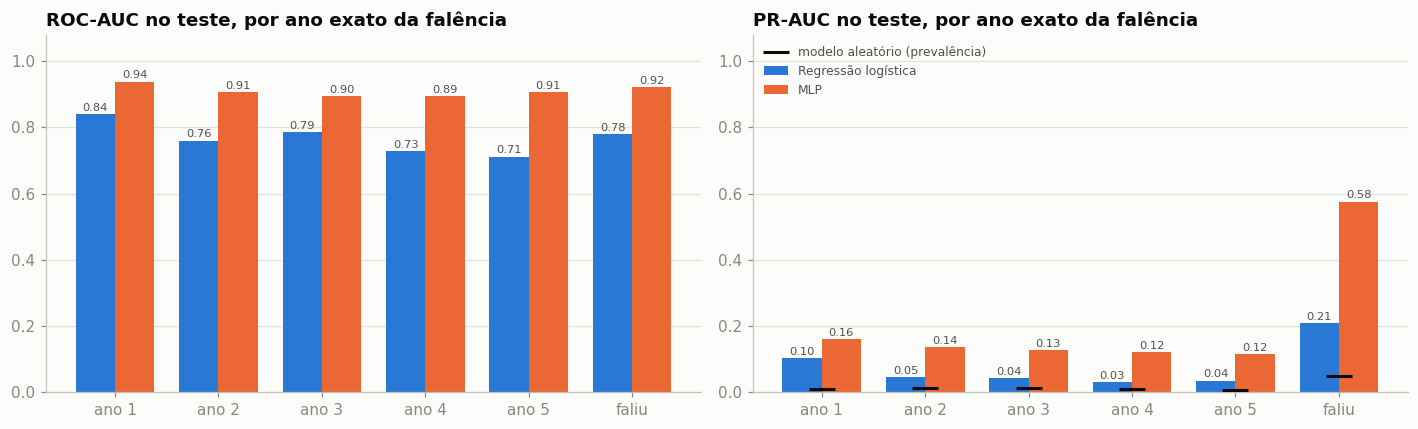

In [8]:
ROTULOS = [f'ano {h}' for h in HORIZONTES] + ['faliu']
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
x = np.arange(len(ROTULOS))
for ax, met in zip(axes, ['ROC-AUC', 'PR-AUC']):
    for j, m in enumerate(MODELOS):
        v = por_h.loc[m, [f'{met} {r}' for r in ROTULOS]].astype(float).values
        ax.bar(x + (j - 0.5) * 0.38, v, width=0.38, color=COR[m], label=m)
        for xi, vi in zip(x + (j - 0.5) * 0.38, v):
            ax.text(xi, vi + 0.01, f'{vi:.2f}', ha='center', fontsize=7.5)
    if met == 'PR-AUC':
        prev = por_h.loc['prevalência (modelo aleatório)', [f'PR-AUC {r}' for r in ROTULOS]].astype(float).values
        ax.scatter(x, prev, marker='_', s=300, color=TINTA, label='modelo aleatório (prevalência)', zorder=3)
    ax.set_xticks(x, ROTULOS)
    ax.set_ylim(0, 1.08)
    ax.set_title(f'{met} no teste, por ano exato da falência')
    ax.grid(axis='x', visible=False)
axes[1].legend(fontsize=8, loc='upper left')
plt.tight_layout()

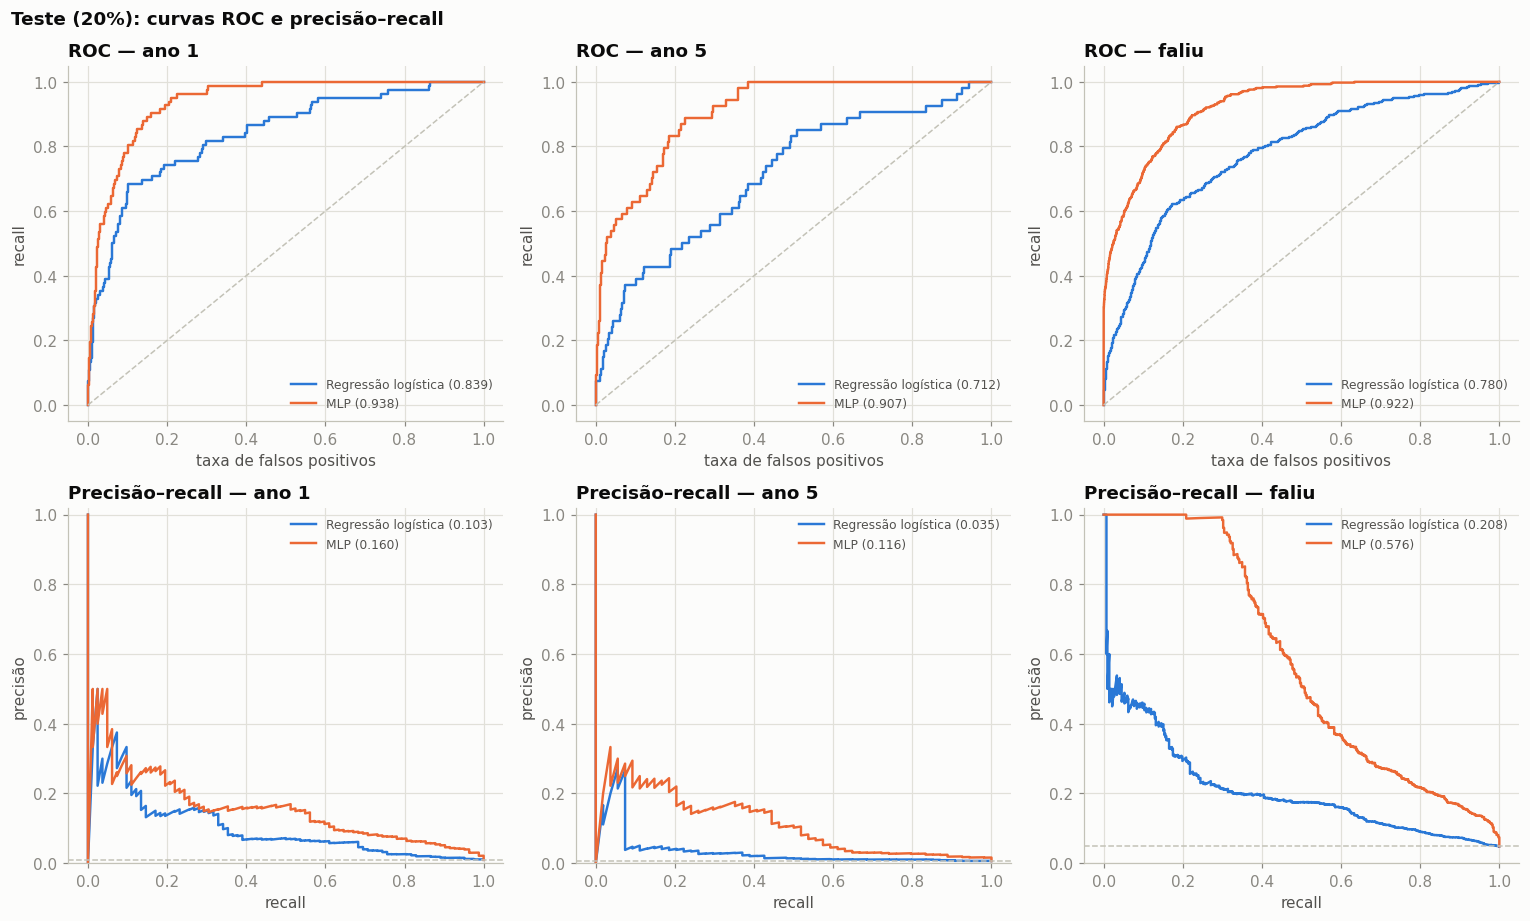

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8.5))
CURVAS = []
for col, (rot, h) in enumerate([('ano 1', 1), ('ano 5', 5), ('faliu', None)]):
    yb = (y_te > 0).astype(int) if h is None else rotulo_ano(y_te, h)
    for m in MODELOS:
        s = prob_faliu(PREV[m]['P_te']) if h is None else prob_ano(PREV[m]['P_te'], h)
        fpr, tpr, _ = roc_curve(yb, s)
        prec, rec, _ = precision_recall_curve(yb, s)
        axes[0, col].plot(fpr, tpr, color=COR[m], linewidth=1.6, label=f'{m} ({roc_auc_score(yb, s):.3f})')
        axes[1, col].plot(rec, prec, color=COR[m], linewidth=1.6, label=f'{m} ({average_precision_score(yb, s):.3f})')
        grade = np.linspace(0, 1, 51)
        CURVAS += [{'curva': 'ROC', 'alvo': rot, 'modelo': m, 'x': g, 'y': float(np.interp(g, fpr, tpr))} for g in grade]
        ordem = np.argsort(rec)
        CURVAS += [{'curva': 'PR', 'alvo': rot, 'modelo': m, 'x': g,
                    'y': float(np.max(prec[rec >= g])) if (rec >= g).any() else 0.0} for g in grade]
    axes[0, col].plot([0, 1], [0, 1], color=EIXO, linestyle='--', linewidth=1)
    axes[0, col].set(xlabel='taxa de falsos positivos', ylabel='recall', title=f'ROC — {rot}')
    axes[1, col].axhline(yb.mean(), color=EIXO, linestyle='--', linewidth=1)
    axes[1, col].set(xlabel='recall', ylabel='precisão', ylim=(0, 1.02), title=f'Precisão–recall — {rot}')
    axes[0, col].legend(fontsize=8, loc='lower right')
    axes[1, col].legend(fontsize=8, loc='upper right')
fig.suptitle('Teste (20%): curvas ROC e precisão–recall', x=0.01, ha='left', fontweight='bold', color=TINTA)
plt.tight_layout()
CURVAS = pd.DataFrame(CURVAS)

## 3. Incerteza no teste (bootstrap)

1000 reamostragens do teste. IC de 95% da PR-AUC média (anos 1 a 5) de cada modelo e da **diferença pareada** em
relação à MLP (as mesmas reamostragens para os dois modelos). Se o IC da diferença contém 0, a diferença não se
distingue do ruído.

In [10]:
rng = np.random.default_rng(0)
B = 200 if RAPIDO else 1000
amostras = [rng.integers(0, len(y_te), len(y_te)) for _ in range(B)]
amostras = [i for i in amostras if all(rotulo_ano(y_te[i], h).sum() > 0 for h in HORIZONTES)]


def pr_media(y, P):
    return np.mean([average_precision_score(rotulo_ano(y, h), prob_ano(P, h)) for h in HORIZONTES])


boot = {m: np.array([pr_media(y_te[i], PREV[m]['P_te'][i]) for i in amostras]) for m in MODELOS}
ic = pd.DataFrame({m: {'PR-AUC média teste': pr_media(y_te, PREV[m]['P_te']),
                       'IC95%': f'[{np.percentile(boot[m], 2.5):.3f}, {np.percentile(boot[m], 97.5):.3f}]',
                       'Δ vs MLP': pr_media(y_te, PREV[m]['P_te']) - pr_media(y_te, PREV['MLP']['P_te']),
                       'IC95% Δ': '—' if m == 'MLP' else f"[{np.percentile(boot[m] - boot['MLP'], 2.5):+.3f}, "
                                                         f"{np.percentile(boot[m] - boot['MLP'], 97.5):+.3f}]"}
                   for m in MODELOS}).T
ic

,PR-AUC média teste,IC95%,Δ vs MLP,IC95% Δ
Regressão logística,0.051773,"[0.044, 0.070]",-0.080544,"[-0.106, -0.062]"
MLP,0.132317,"[0.122, 0.162]",0.0,—


## 4. Matrizes de confusão: validação e teste

**(a) Faliu ou não (em algum dos 5 anos).** Escore $1 - P(y = 0)$. O limiar de cada modelo é escolhido **na
validação**: o percentil 95 do escore entre as empresas que não faliram nas previsões fora da amostra da CV (5% de
falsos positivos). O mesmo limiar é aplicado ao teste, sem reajuste.

**(b) Em que ano?** Entre as empresas que faliram, o ano verdadeiro contra o ano mais provável segundo o modelo
($\arg\max_{h \ge 1} P(y = h)$).

In [11]:
LIMIAR = {}
mconf = []
for m in MODELOS:
    s_v, s_t = prob_faliu(PREV[m]['P_oof']), prob_faliu(PREV[m]['P_te'])
    LIMIAR[m] = np.quantile(s_v[y_tr == 0], 1 - FPR_ALVO)
    for conj, sc, y in [('validação (CV)', s_v, y_tr), ('teste', s_t, y_te)]:
        yb, pred = (y > 0).astype(int), (sc > LIMIAR[m]).astype(int)
        vn, fp, fn, vp = confusion_matrix(yb, pred, labels=[0, 1]).ravel()
        mconf.append({'modelo': m, 'conjunto': conj, 'limiar': LIMIAR[m], 'VN': vn, 'FP': fp, 'FN': fn, 'VP': vp,
                      'recall': vp / (vp + fn), 'precisão': vp / (vp + fp), 'taxa de FP': fp / (fp + vn)})
mconf = pd.DataFrame(mconf).set_index(['modelo', 'conjunto'])
mconf.round(3)

limiar     VN    FP    FN   VP  recall  precisão  taxa de FP
modelo              conjunto                                                                    
Regressão logística validação (CV)   0.135  31100  1637  1215  451   0.271     0.216       0.050
                    teste            0.135   7732   452   294  123   0.295     0.214       0.055
MLP                 validação (CV)   0.173  31100  1637   697  969   0.582     0.372       0.050
                    teste            0.173   7794   390   174  243   0.583     0.384       0.048

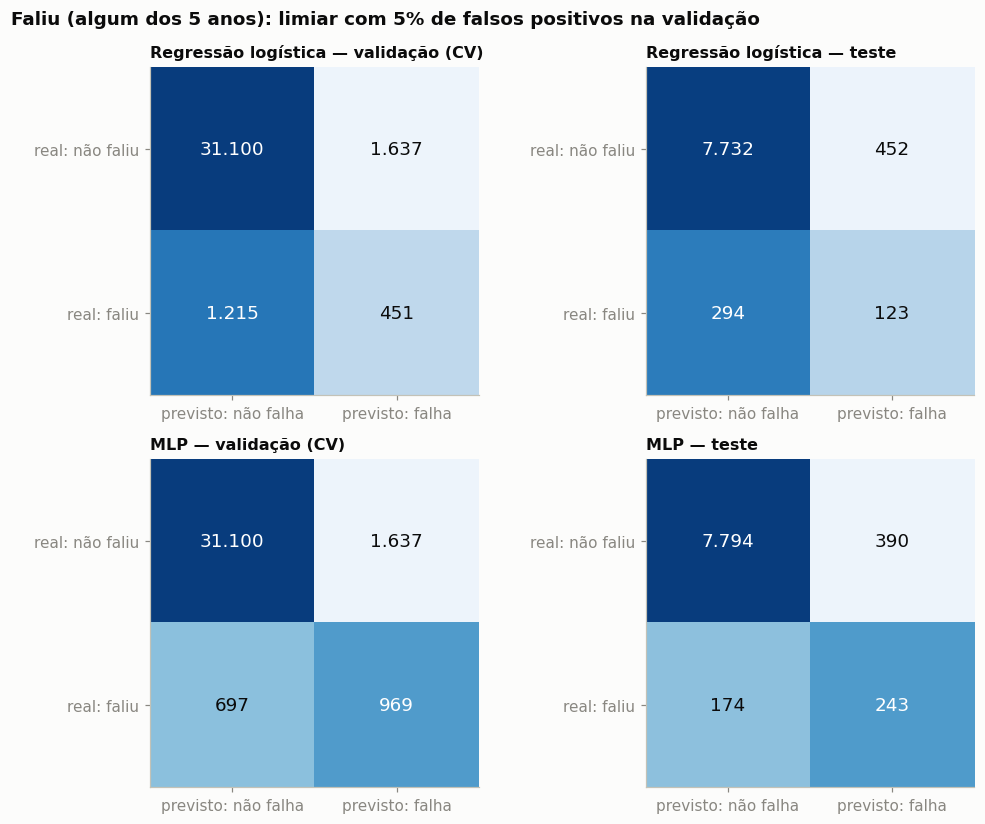

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(9.5, 7.6))
for i, m in enumerate(MODELOS):
    for j, conj in enumerate(['validação (CV)', 'teste']):
        lin = mconf.loc[(m, conj)]
        cm = np.array([[lin['VN'], lin['FP']], [lin['FN'], lin['VP']]], dtype=int)
        ax = axes[i, j]
        ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap='Blues', vmin=0, vmax=1)
        for (a, b), v in np.ndenumerate(cm):
            ax.text(b, a, f'{v:,}'.replace(',', '.'), ha='center', va='center',
                    color='white' if cm[a, b] / cm[a].sum() > 0.5 else TINTA, fontsize=12)
        ax.set_xticks([0, 1], ['previsto: não falha', 'previsto: falha'])
        ax.set_yticks([0, 1], ['real: não faliu', 'real: faliu'])
        ax.set_title(f'{m} — {conj}', fontsize=10.5)
        ax.grid(False)
fig.suptitle('Faliu (algum dos 5 anos): limiar com 5% de falsos positivos na validação', x=0.01, ha='left',
             fontweight='bold', color=TINTA)
plt.tight_layout()

In [13]:
conf, CM_ANO = {}, {}
for m in MODELOS:
    for conj, P, y in [('validação (CV)', PREV[m]['P_oof'], y_tr), ('teste', PREV[m]['P_te'], y_te)]:
        fal = y > 0
        prev_h = P[fal, 1:].argmax(axis=1) + 1
        CM_ANO[(m, conj)] = pd.DataFrame(confusion_matrix(y[fal], prev_h, labels=HORIZONTES),
                                         index=[f'verdadeiro ano {h}' for h in HORIZONTES],
                                         columns=[f'previsto ano {h}' for h in HORIZONTES])
        conf[(m, conj)] = {'acerto exato do ano': np.mean(prev_h == y[fal]),
                           'acerto ±1 ano': np.mean(np.abs(prev_h - y[fal]) <= 1),
                           'acerto ao acaso (ano mais comum)': np.bincount(y[fal])[1:].max() / fal.sum()}
conf = pd.DataFrame(conf).T
display(conf.round(3))
cm_mlp_val, cm_mlp = CM_ANO[('MLP', 'validação (CV)')], CM_ANO[('MLP', 'teste')]
print('MLP — ano verdadeiro × previsto (só empresas que faliram), validação e teste:')
display(cm_mlp_val)
cm_mlp

acerto exato do ano  acerto ±1 ano  acerto ao acaso (ano mais comum)
Regressão logística validação (CV)                0.264          0.672                             0.246
                    teste                         0.271          0.655                             0.247
MLP                 validação (CV)                0.261          0.696                             0.246
                    teste                         0.247          0.671                             0.247

MLP — ano verdadeiro × previsto (só empresas que faliram), validação e teste:


,previsto ano 1,previsto ano 2,previsto ano 3,previsto ano 4,previsto ano 5
verdadeiro ano 1,86,129,72,36,3
verdadeiro ano 2,70,159,117,55,9
verdadeiro ano 3,55,136,118,66,19
verdadeiro ano 4,30,91,119,48,31
verdadeiro ano 5,9,59,69,57,23


,previsto ano 1,previsto ano 2,previsto ano 3,previsto ano 4,previsto ano 5
verdadeiro ano 1,24,31,22,4,1
verdadeiro ano 2,21,35,32,12,3
verdadeiro ano 3,10,39,30,15,5
verdadeiro ano 4,6,32,26,10,5
verdadeiro ano 5,4,19,19,8,4


## 5. Testes estatísticos: a MLP é melhor de verdade?

O intervalo de *bootstrap* da seção 3 já é pareado; aqui entram testes mais potentes, todos **pareados** (os dois
modelos avaliados nas mesmas empresas ou nos mesmos folds), com correção de Holm dentro de cada família de testes:

**No teste (20%, 8.601 empresas), para cada ano exato e para "faliu":**
- **PR-AUC**: *bootstrap* pareado estratificado (2.000 reamostras) e **teste de permutação pareado** (2.000 trocas:
  sob H0, trocar as previsões dos dois modelos em cada empresa não muda nada);
- **ROC-AUC**: **teste de DeLong** para AUCs correlacionadas (exato no sentido assintótico, sem reamostragem);
- **recall a 5% de falsos positivos** (limiar escolhido na validação, seção 4): **teste exato de McNemar** sobre as
  falidas que só um dos modelos detecta.

**Na validação cruzada repetida (3 × 5 = 15 folds do treino):** **t corrigido de Nadeau e Bengio** sobre as 15
diferenças por fold, para PR-AUC média, PR-AUC de "faliu" e ROC-AUC média.

In [14]:
B_TESTE, N_PERM = (200, 200) if RAPIDO else (2000, 2000)
P_M, P_L = PREV['MLP']['P_te'], PREV['Regressão logística']['P_te']
ALVOS = [(f'ano {h}', rotulo_ano(y_te, h), P_M[:, h], P_L[:, h]) for h in HORIZONTES] + \
        [('faliu', (y_te > 0).astype(int), prob_faliu(P_M), prob_faliu(P_L))]
linhas = []
for alvo, yb, sm, sl in ALVOS:
    amostras = amostras_bootstrap(yb, B_TESTE, semente=SEMENTE)
    b = bootstrap_pareado(average_precision_score, yb, sm, sl, amostras)
    p_perm = permutacao_pareada(average_precision_score, yb, sm, sl, N_PERM, semente=SEMENTE)
    d = delong(yb, sm, sl)
    lin = {'alvo': alvo, 'falências': int(yb.sum()),
           'PR-AUC MLP': average_precision_score(yb, sm), 'PR-AUC logística': average_precision_score(yb, sl),
           'Δ PR-AUC': b['diferença'], 'IC 95% Δ': f"[{b['IC 95% inf.']:+.3f}, {b['IC 95% sup.']:+.3f}]",
           'p bootstrap': b['p (bootstrap)'], 'p permutação': p_perm,
           'ROC-AUC MLP': d['AUC 1'], 'ROC-AUC logística': d['AUC 2'], 'p DeLong': d['p (DeLong)']}
    if alvo == 'faliu':
        fal = yb == 1
        mc = mcnemar(sm[fal] > LIMIAR['MLP'], sl[fal] > LIMIAR['Regressão logística'])
        lin.update({'recall MLP (5% FP)': np.mean(sm[fal] > LIMIAR['MLP']),
                    'recall logística (5% FP)': np.mean(sl[fal] > LIMIAR['Regressão logística']),
                    'só a MLP detecta': mc['só A acerta'], 'só a logística detecta': mc['só B acerta'],
                    'p McNemar': mc['p (McNemar)']})
    linhas.append(lin)
testes_te = pd.DataFrame(linhas).set_index('alvo')
for col in ['p bootstrap', 'p permutação', 'p DeLong']:
    testes_te[col + ' (Holm)'] = holm(testes_te[col])
print('Teste: MLP contra regressão logística (p-valores bilaterais; Holm sobre os 6 alvos de cada teste)')
testes_te.round(4)

Teste: MLP contra regressão logística (p-valores bilaterais; Holm sobre os 6 alvos de cada teste)


,falências,PR-AUC MLP,PR-AUC logística,Δ PR-AUC,IC 95% Δ,p bootstrap,p permutação,ROC-AUC MLP,ROC-AUC logística,p DeLong,recall MLP (5% FP),recall logística (5% FP),só a MLP detecta,só a logística detecta,p McNemar,p bootstrap (Holm),p permutação (Holm),p DeLong (Holm)
alvo,,,,,,,,,,,,,,,,,,
ano 1,82,0.1596,0.1033,0.0563,"[-0.001, +0.125]",0.0540,0.0875,0.9378,0.8391,0.0,NaN,NaN,NaN,NaN,NaN,0.054,0.1039,0.0
ano 2,103,0.1374,0.0461,0.0913,"[+0.059, +0.141]",0.0005,0.0005,0.9066,0.7598,0.0,NaN,NaN,NaN,NaN,NaN,0.003,0.0030,0.0
ano 3,99,0.1279,0.0430,0.0849,"[+0.048, +0.133]",0.0005,0.0030,0.8952,0.7854,0.0,NaN,NaN,NaN,NaN,NaN,0.003,0.0120,0.0
ano 4,79,0.1208,0.0310,0.0898,"[+0.052, +0.159]",0.0005,0.0095,0.8945,0.7275,0.0,NaN,NaN,NaN,NaN,NaN,0.003,0.0285,0.0
ano 5,54,0.1159,0.0354,0.0804,"[+0.016, +0.171]",0.0210,0.0520,0.9072,0.7120,0.0,NaN,NaN,NaN,NaN,NaN,0.042,0.1039,0.0
faliu,417,0.5759,0.2080,0.3679,"[+0.323, +0.410]",0.0005,0.0005,0.9225,0.7799,0.0,0.5827,0.295,139.0,19.0,0.0,0.003,0.0030,0.0


In [15]:
# Validação cruzada repetida (mesmas 3 divisões de 5 folds para os dois modelos)
REP = {'MLP': carregar_previsoes('mlp_rep')['P_oof'], 'Regressão logística': carregar_previsoes('logistica_rep')['P_oof']}
R = min(len(REP['MLP']), len(REP['Regressão logística']))
DIVS = {r: (DIV if r == 0 else folds(y_tr, N_FOLDS, r)) for r in range(R)}
linhas = []
for met in ['PR-AUC média', 'PR-AUC faliu', 'ROC-AUC média', 'Recall@FPR5% médio']:
    f = {m: np.array([metricas(y_tr[iva], REP[m][r][iva])[met] for r in range(R) for _, iva in DIVS[r]]) for m in MODELOS}
    dif, t, p, gl = t_corrigido(f['MLP'] - f['Regressão logística'], 1 / (N_FOLDS - 1))
    linhas.append({'métrica': met, 'MLP (média dos folds)': f['MLP'].mean(),
                   'logística (média dos folds)': f['Regressão logística'].mean(), 'Δ (MLP − logística)': dif,
                   'folds em que a MLP é melhor': f"{int((f['MLP'] > f['Regressão logística']).sum())} de {len(f['MLP'])}",
                   't corrigido': t, 'graus de liberdade': gl, 'p': p})
testes_cv = pd.DataFrame(linhas).set_index('métrica')
testes_cv['p (Holm)'] = holm(testes_cv['p'])
print(f'Validação cruzada repetida ({R} × {N_FOLDS} folds): teste t corrigido de Nadeau-Bengio')
testes_cv.round(4)

Validação cruzada repetida (3 × 5 folds): teste t corrigido de Nadeau-Bengio


,MLP (média dos folds),logística (média dos folds),Δ (MLP − logística),folds em que a MLP é melhor,t corrigido,graus de liberdade,p,p (Holm)
métrica,,,,,,,,
PR-AUC média,0.1451,0.0501,0.0950,15 de 15,19.7722,14,0.0,0.0
PR-AUC faliu,0.5701,0.1962,0.3739,15 de 15,25.3255,14,0.0,0.0
ROC-AUC média,0.9001,0.7591,0.1410,15 de 15,28.6622,14,0.0,0.0
Recall@FPR5% médio,0.5374,0.2610,0.2764,15 de 15,15.4785,14,0.0,0.0


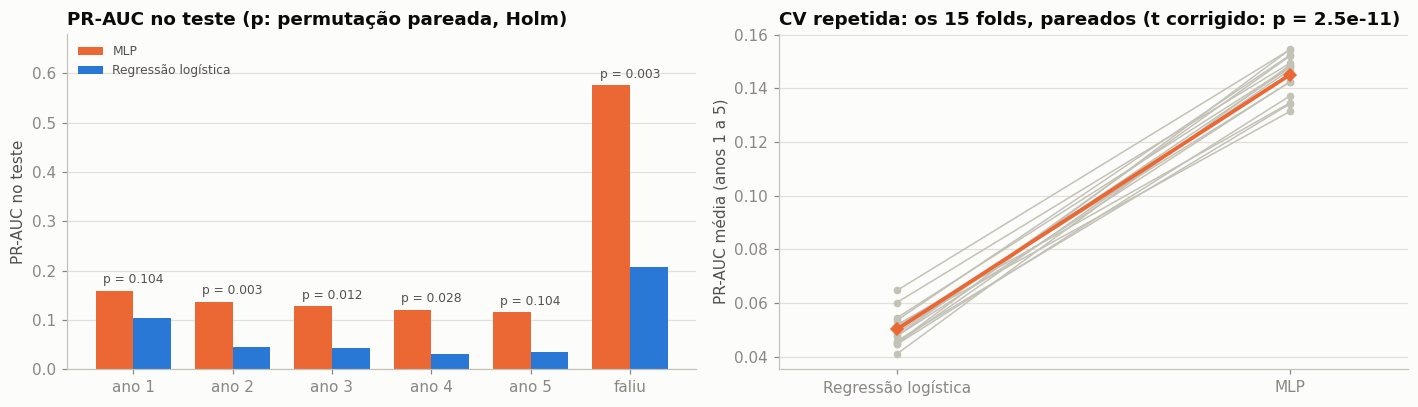

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
x = np.arange(len(testes_te))
for j, (m, col) in enumerate([('MLP', 'PR-AUC MLP'), ('Regressão logística', 'PR-AUC logística')]):
    axes[0].bar(x + (j - 0.5) * 0.38, testes_te[col], width=0.38, color=COR[m], label=m)
for xi, (p, top) in enumerate(zip(testes_te['p permutação (Holm)'], testes_te[['PR-AUC MLP', 'PR-AUC logística']].max(axis=1))):
    axes[0].text(xi, top + 0.015, 'p < 0,001' if p < 0.001 else f'p = {p:.3f}', ha='center', fontsize=8, color=TINTA2)
axes[0].set_xticks(x, testes_te.index)
axes[0].set_ylim(0, testes_te[['PR-AUC MLP', 'PR-AUC logística']].values.max() * 1.18)
axes[0].set_ylabel('PR-AUC no teste')
axes[0].set_title('PR-AUC no teste (p: permutação pareada, Holm)')
axes[0].legend(fontsize=8, loc='upper left')
axes[0].grid(axis='x', visible=False)

f = {m: np.array([metricas(y_tr[iva], REP[m][r][iva])['PR-AUC média'] for r in range(R) for _, iva in DIVS[r]]) for m in MODELOS}
for k in range(len(f['MLP'])):
    axes[1].plot([0, 1], [f['Regressão logística'][k], f['MLP'][k]], color=EIXO, linewidth=1, marker='o', markersize=4)
axes[1].plot([0, 1], [f['Regressão logística'].mean(), f['MLP'].mean()], color=COR['MLP'], linewidth=2.5, marker='D')
axes[1].set_xticks([0, 1], ['Regressão logística', 'MLP'])
axes[1].set_xlim(-0.3, 1.3)
axes[1].set_ylabel('PR-AUC média (anos 1 a 5)')
p_cv = testes_cv.loc['PR-AUC média', 'p (Holm)']
axes[1].set_title(f'CV repetida: os {len(f["MLP"])} folds, pareados (t corrigido: p = {p_cv:.1e})')
axes[1].grid(axis='x', visible=False)
plt.tight_layout()

## 6. Redução de dimensão: em que momento entra e o que sobra

Escala, imputação, filtro de correlação + VIF, PCA, oversampling e SMOTE são passos de um *Pipeline*. Na validação
cruzada, o *Pipeline* inteiro é ajustado **só nos 4 folds de treino** de cada rodada e depois aplicado ao fold de
validação; oversampling e SMOTE geram exemplos só nesses 4 folds (o fold de validação e o teste nunca são
reamostrados). No modelo final, o ajuste é feito em todo o treino e aplicado ao teste. Abaixo, o que o filtro e o
PCA produzem com a escala por quantis, em cada fold e no treino completo. Entram os 63 indicadores (sem colunas novas).

In [17]:
from sklearn.pipeline import Pipeline as _Pipe
ESC_SEL = 'quantis (normal)'
selecao = []
for k, (itr, _) in enumerate(DIV + [(np.arange(len(y_tr)), None)], 1):
    nome = f'fold {k}' if k <= len(DIV) else 'treino completo'
    f_cv = _Pipe(passos_preparo(ESC_SEL, 'corr + VIF')).fit(X_tr.iloc[itr], y_tr[itr]).named_steps['selecao']
    pca = _Pipe(passos_preparo(ESC_SEL, 'PCA 95%')).fit(X_tr.iloc[itr], y_tr[itr]).named_steps['selecao']
    selecao.append({'ajuste': nome, 'indicadores de entrada': len(VARS), 'mantidos (corr + VIF)': len(f_cv.colunas_),
                    'removidos por correlação': len(f_cv.removidas_corr_), 'removidos por VIF': len(f_cv.removidas_vif_),
                    'componentes do PCA (95%)': pca.n_components_})
selecao = pd.DataFrame(selecao).set_index('ajuste')
selecao

,indicadores de entrada,mantidos (corr + VIF),removidos por correlação,removidos por VIF,componentes do PCA (95%)
ajuste,,,,,
fold 1,63,25,31,7,22
fold 2,63,24,32,7,22
fold 3,63,25,31,7,22
fold 4,63,24,32,7,21
fold 5,63,25,31,7,22
treino completo,63,25,31,7,22


In [18]:
filtro = _Pipe(passos_preparo(ESC_SEL, 'corr + VIF')).fit(X_tr, y_tr).named_steps['selecao']
desc = pd.read_csv('resumo_variaveis.csv', index_col=0)['descricao']
lista_sel = pd.DataFrame(
    [{'coluna': c, 'situação': 'mantida', 'motivo': '', 'descrição': desc.get(c, '')} for c in filtro.colunas_] +
    [{'coluna': c, 'situação': 'removida', 'motivo': f'|r| > 0,8 com {o}', 'descrição': desc.get(c, '')}
     for c, o in filtro.removidas_corr_.items()] +
    [{'coluna': c, 'situação': 'removida', 'motivo': f'VIF = {v:.1f}', 'descrição': desc.get(c, '')}
     for c, v in filtro.removidas_vif_])
pd.set_option('display.max_rows', 120)
lista_sel

,coluna,situação,motivo,descrição
0,X26,mantida,,(lucro líquido+depr.) / passivo total
1,X24,mantida,,lucro bruto (3 anos) / ativo total
2,X39,mantida,,lucro s/ vendas / vendas
3,X25,mantida,,(PL - capital social) / ativo total
4,X45,mantida,,lucro líquido / estoque
5,X55,mantida,,capital de giro (absoluto)
6,X56,mantida,,(vendas - CPV) / vendas
7,X5,mantida,,liquidez em dias (caixa+títulos+receb.-passivo...
8,X54,mantida,,capital permanente / imobilizado
9,X63,mantida,,vendas / passivo CP


## 7. Calibração (curva de calibração, Brier e log loss)

A calibração verifica se as probabilidades podem ser lidas ao pé da letra: entre as empresas com probabilidade
prevista de 10%, cerca de 10% deveriam falir. Para cada horizonte (falir em até 1, 3 e 5 anos, com
P(até h) = P(y=1) + … + P(y=h)), as empresas do teste são agrupadas em 10 faixas pelos decis da probabilidade prevista,
e comparamos a probabilidade média prevista com a taxa observada em cada faixa. Um modelo bem calibrado fica sobre a
diagonal. Também calculamos o índice de Brier, a log loss, o Brier de referência (prever sempre a prevalência) e o
erro de calibração esperado (ECE: diferença média entre previsto e observado, ponderada pelo tamanho das faixas).


Brier  Brier de referência (prevalência)  Brier skill score  log loss  prob. média prevista  taxa observada     ECE
horizonte    modelo                                                                                                                                   
até 1 ano(s) Regressão logística  0.0090                             0.0094             0.0449    0.0443                0.0098          0.0095  0.0028
             MLP                  0.0087                             0.0094             0.0837    0.0369                0.0101          0.0095  0.0009
até 3 ano(s) Regressão logística  0.0298                             0.0319             0.0677    0.1240                0.0338          0.0330  0.0048
             MLP                  0.0245                             0.0319             0.2335    0.0924                0.0343          0.0330  0.0031
até 5 ano(s) Regressão logística  0.0424                             0.0461             0.0818    0.1676                0.0495          0.0485  0.0103
             MLP                  0.0299                             0.0461             0.3527    0.1127                0.0501          0.0485  0.0037

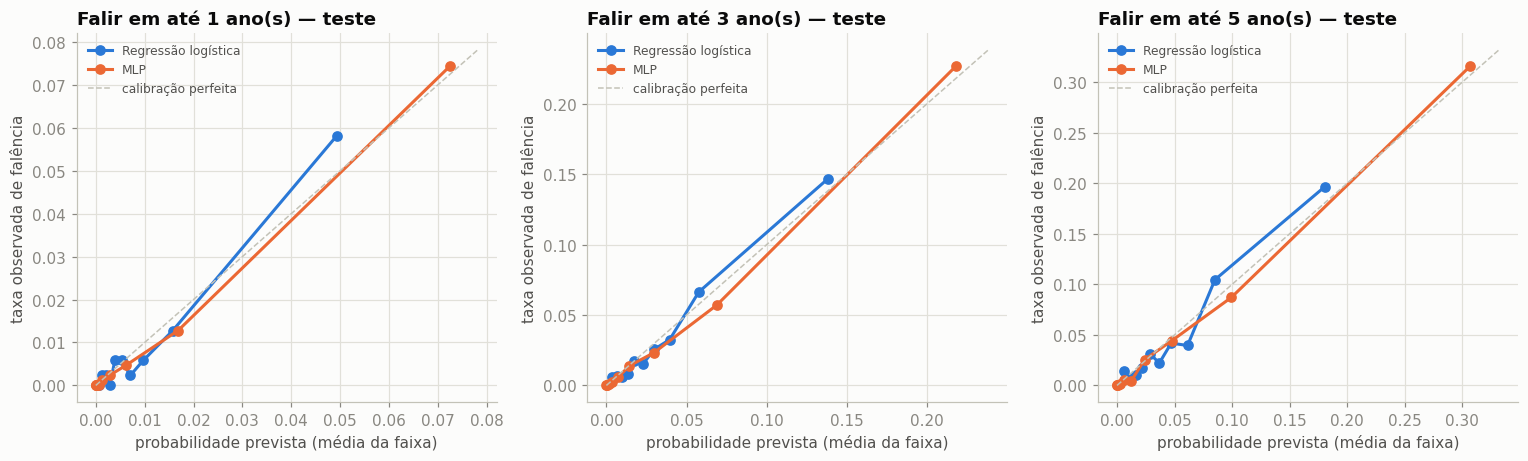

In [19]:
from sklearn.metrics import brier_score_loss, log_loss

CAL_H = [1, 3, 5]
calib, calib_pts = [], []
fig, axes = plt.subplots(1, 3, figsize=(14, 4.3))
for ax, h in zip(axes, CAL_H):
    yb = ((y_te >= 1) & (y_te <= h)).astype(int)
    topo = 0
    for m in MODELOS:
        s = PREV[m]['P_te'][:, 1:h + 1].sum(axis=1)
        g = pd.DataFrame({'p': s, 'y': yb, 'faixa': pd.qcut(s, 10, labels=False, duplicates='drop')})
        g = g.groupby('faixa').agg(p=('p', 'mean'), y=('y', 'mean'), n=('y', 'size'))
        ax.plot(g['p'], g['y'], marker='o', color=COR[m], label=m)
        topo = max(topo, g['p'].max(), g['y'].max())
        calib_pts += [{'horizonte': f'até {h} ano(s)', 'modelo': m, 'faixa': k + 1, 'prob. média prevista': r.p,
                       'taxa observada': r.y, 'n': int(r.n)} for k, r in enumerate(g.itertuples())]
        pi = yb.mean()
        calib.append({'horizonte': f'até {h} ano(s)', 'modelo': m, 'Brier': brier_score_loss(yb, s),
                      'Brier de referência (prevalência)': pi * (1 - pi),
                      'Brier skill score': 1 - brier_score_loss(yb, s) / (pi * (1 - pi)),
                      'log loss': log_loss(yb, np.clip(s, 1e-7, 1 - 1e-7)),
                      'prob. média prevista': s.mean(), 'taxa observada': pi,
                      'ECE': float(np.sum(g['n'] * (g['p'] - g['y']).abs()) / g['n'].sum())})
    ax.plot([0, topo * 1.05], [0, topo * 1.05], color=EIXO, linestyle='--', linewidth=1, label='calibração perfeita')
    ax.set(xlabel='probabilidade prevista (média da faixa)', ylabel='taxa observada de falência',
           title=f'Falir em até {h} ano(s) — teste')
    ax.legend(fontsize=8, loc='upper left')
plt.tight_layout()
calib = pd.DataFrame(calib).set_index(['horizonte', 'modelo'])
calib_pts = pd.DataFrame(calib_pts)
calib.round(4)


## 8. Quando o modelo de aprendizagem profunda falha?

Olhamos onde a MLP erra, comparando com a regressão logística. Usamos a pergunta "faliu em algum dos 5 anos?" e o
ponto de operação com **5% de falsos positivos** (limiar escolhido na validação, seção 4).

Recortes:
1. **ano verdadeiro** da falência;
2. **faltantes** no balanço;
3. **valores extremos**: número de indicadores fora da faixa 1–99% do treino;
4. **porte** da empresa (X29 = log do ativo total), em quartis do treino.

In [20]:
detecta = {m: prob_faliu(PREV[m]['P_te']) > LIMIAR[m] for m in MODELOS}
fal = y_te > 0
rec_h = pd.DataFrame({m: {f'faliu no ano {k} (n = {(y_te == k).sum()})': detecta[m][y_te == k].mean() for k in HORIZONTES}
                      for m in MODELOS})
rec_h.loc['todas as falências'] = {m: detecta[m][fal].mean() for m in MODELOS}
print('Recall a 5% de falsos positivos, por ano verdadeiro da falência (teste):')
rec_h.round(3)

Recall a 5% de falsos positivos, por ano verdadeiro da falência (teste):


,Regressão logística,MLP
faliu no ano 1 (n = 82),0.451,0.659
faliu no ano 2 (n = 103),0.282,0.573
faliu no ano 3 (n = 99),0.273,0.566
faliu no ano 4 (n = 79),0.228,0.532
faliu no ano 5 (n = 54),0.222,0.593
todas as falências,0.295,0.583


In [21]:
lim_inf, lim_sup = tr[VARS].quantile(0.01), tr[VARS].quantile(0.99)
recortes = pd.DataFrame({
    'faltantes': pd.cut(te[VARS].isna().sum(axis=1), [-1, 0, 2, 100], labels=['0', '1–2', '3+']),
    'valores extremos': pd.cut(((te[VARS] < lim_inf) | (te[VARS] > lim_sup)).sum(axis=1), [-1, 0, 2, 100],
                               labels=['0', '1–2', '3+']),
    'porte (X29)': pd.cut(te['X29'], [-np.inf, *tr['X29'].quantile([0.25, 0.5, 0.75]).values, np.inf],
                          labels=['Q1 (menores)', 'Q2', 'Q3', 'Q4 (maiores)']),
})
linhas = []
for rec in recortes:
    for g in recortes[rec].cat.categories:
        idx = (recortes[rec] == g).values
        yb = (y_te[idx] > 0).astype(int)
        lin = {'recorte': rec, 'grupo': g, 'n': int(idx.sum()), 'falências': int(yb.sum()), '% falência': 100 * yb.mean()}
        for m in MODELOS:
            ok_ = yb.sum() >= 5 and yb.sum() < len(yb)
            lin[f'PR-AUC {m}'] = average_precision_score(yb, prob_faliu(PREV[m]['P_te'][idx])) if ok_ else np.nan
            lin[f'recall {m}'] = detecta[m][idx & fal].mean() if (idx & fal).sum() else np.nan
        linhas.append(lin)
recortes_tab = pd.DataFrame(linhas).set_index(['recorte', 'grupo'])
recortes_tab.round(3)

n  falências  % falência  PR-AUC Regressão logística  recall Regressão logística  PR-AUC MLP  recall MLP
recorte          grupo                                                                                                                    
faltantes        0             6441        148       2.298                       0.129                       0.284       0.376       0.527
                 1–2           1735        231      13.314                       0.340                       0.299       0.738       0.649
                 3+             425         38       8.941                       0.177                       0.316       0.286       0.395
valores extremos 0             6237        239       3.832                       0.199                       0.192       0.599       0.565
                 1–2           1415         82       5.795                       0.233                       0.317       0.563       0.573
                 3+             949         96      10.116                       0.288                       0.531       0.509       0.635
porte (X29)      Q1 (menores)  2205        154       6.984                       0.170                       0.338       0.320       0.429
                 Q2            2147         96       4.471                       0.267                       0.281       0.530       0.531
                 Q3            2132         96       4.503                       0.314                       0.250       0.791       0.729
                 Q4 (maiores)  2115         71       3.357                       0.254                       0.282       0.772       0.789

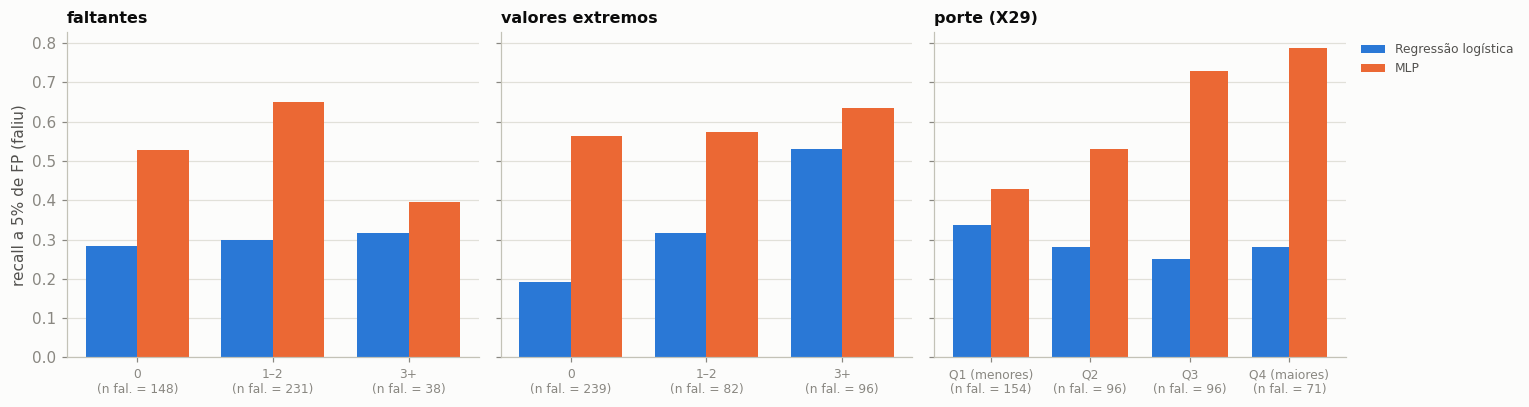

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, rec in zip(axes, recortes):
    sub = recortes_tab.loc[rec]
    x = np.arange(len(sub))
    for j, m in enumerate(MODELOS):
        ax.bar(x + (j - 0.5) * 0.38, sub[f'recall {m}'], width=0.38, color=COR[m], label=m)
    ax.set_xticks(x, [f'{g}\n(n fal. = {n})' for g, n in zip(sub.index, sub['falências'])], fontsize=8)
    ax.set_title(rec, fontsize=10.5)
    ax.grid(axis='x', visible=False)
axes[0].set_ylabel('recall a 5% de FP (faliu)')
axes[-1].legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout()

## 9. Custo computacional

Tempos medidos na execução dos notebooks 03 (CPU) e 04 (GPU). No notebook 04, os 5 *folds* de cada validação cruzada e as 5 sementes do modelo final rodam em paralelo na GPU.

In [23]:

t03, c04 = carregar_json('config_03')['tempo_s'], carregar_json('config_04')
custo = pd.DataFrame([{'notebook': '03 (CPU)', 'etapa': k, 'minutos': v / 60} for k, v in t03.items()] +
                     [{'notebook': f"04 ({c04['dispositivo']})", 'etapa': 'MLP: ' + k, 'minutos': v}
                      for k, v in c04['tempo_min'].items()])
cfg_m = c04['MLP']
print(f"MLP final: {'-'.join(map(str, cfg_m['camadas']))}, {cfg_m['entradas']} entradas, "
      f"{cfg_m['parâmetros']:,} parâmetros treináveis, média de {cfg_m['sementes']} sementes")
print(f"total: {custo['minutos'].sum():.0f} min")
custo.round(1)

MLP final: 128-64, 24 entradas, 12,230 parâmetros treináveis, média de 5 sementes
total: 678 min


,notebook,etapa,minutos
0,03 (CPU),Logística: fatorial de pré-processamento,14.1
1,03 (CPU),Logística: busca de hiperparâmetros,0.9
2,03 (CPU),Logística: seleção robusta (CV repetida),0.4
3,03 (CPU),Regressão logística: ajuste final,0.0
4,04 (NVIDIA GeForce GTX 1650),MLP: pré-processamento,4.2
5,04 (NVIDIA GeForce GTX 1650),MLP: busca de hiperparâmetros,8.8
6,04 (NVIDIA GeForce GTX 1650),MLP: treino longo,201.1
7,04 (NVIDIA GeForce GTX 1650),MLP: seleção robusta,426.2
8,04 (NVIDIA GeForce GTX 1650),MLP: modelo final,22.3


In [24]:
tvt.to_csv('resultados/treino_validacao_teste_final.csv', encoding='utf-8-sig')
tt.to_csv('resultados/treino_teste.csv', encoding='utf-8-sig')
val.to_csv('resultados/validacao_cv.csv', encoding='utf-8-sig')
val_folds.to_csv('resultados/validacao_por_fold.csv', encoding='utf-8-sig')
mconf.to_csv('resultados/matriz_confusao.csv', encoding='utf-8-sig')
conf.to_csv('resultados/acerto_do_ano.csv', encoding='utf-8-sig')
cm_mlp_val.to_csv('resultados/horizonte_validacao_mlp.csv', encoding='utf-8-sig')
cm_mlp.to_csv('resultados/horizonte_teste_mlp.csv', encoding='utf-8-sig')
selecao.to_csv('resultados/selecao_pca_por_fold.csv', encoding='utf-8-sig')
lista_sel.to_csv('resultados/variaveis_corr_vif.csv', encoding='utf-8-sig', index=False)
por_h.to_csv('resultados/teste_por_horizonte.csv', encoding='utf-8-sig')
CURVAS.to_csv('resultados/curvas_teste.csv', encoding='utf-8-sig', index=False)
calib.to_csv('resultados/calibracao.csv', encoding='utf-8-sig')
calib_pts.to_csv('resultados/calibracao_faixas.csv', encoding='utf-8-sig', index=False)
ic.to_csv('resultados/bootstrap_teste.csv', encoding='utf-8-sig')
rec_h.to_csv('resultados/recall_por_horizonte.csv', encoding='utf-8-sig')
recortes_tab.to_csv('resultados/quando_falha_recortes.csv', encoding='utf-8-sig')
custo.to_csv('resultados/custo_computacional.csv', encoding='utf-8-sig', index=False)
testes_te.to_csv('resultados/testes_estatisticos_teste.csv', encoding='utf-8-sig')
testes_cv.to_csv('resultados/testes_estatisticos_cv.csv', encoding='utf-8-sig')

## Conclusões

- **A MLP é melhor que a logística em todas as métricas, no teste e na CV.**
  - "Faliu ou não": PR-AUC **0,576 contra 0,208** (prevalência 0,048), ROC-AUC 0,92 contra 0,78. A 5% de falsos
    positivos, a MLP encontra **58% das falências** e a logística 29%; das empresas que só um modelo detecta, 139 são
    da MLP e 19 da logística (McNemar, p < 10⁻²²).
  - Ano exato: PR-AUC média 0,132 contra 0,052 (IC 95% da diferença no *bootstrap*: 0,062 a 0,106).
- **Testes no teste, com Holm:** a diferença é significativa nos anos 2, 3 e 4 e em "faliu" pelos três testes
  (*bootstrap*, permutação, DeLong). No ano 1 (82 falências) e no ano 5 (54) a PR-AUC da MLP também é maior, mas o
  IC do *bootstrap* encosta no zero no ano 1 e a permutação não confirma nos anos 1 e 5 (p de Holm 0,10); o DeLong
  (ROC-AUC) é significativo em todos os anos.
- **Testes na CV repetida 3 × 5:** a MLP vence nos 15 folds em todas as métricas (t corrigido, p de Holm < 10⁻⁹).
- **Calibração:** as duas acertam a taxa média (prob. média 0,050 contra 0,048 observada), mas a MLP separa muito
  melhor: Brier skill score de "faliu em até 5 anos" 0,35 contra 0,08; ECE 0,004 contra 0,010.
- **Ano exato é difícil para os dois:** o ano previsto acerta 25–27% das vezes, igual a chutar o ano mais comum; com
  tolerância de ±1 ano, 65–70%. Os balanços de uma empresa que vai falir parecem iguais a 1 ou a 5 anos do fim.
- **Quando a MLP falha:** pior nas empresas **menores** (1º quartil do porte: PR-AUC 0,32 contra 0,77–0,79 nas
  maiores) e nas com **3 ou mais faltantes** (0,29). Valores extremos pesam menos.
- **Custo:** a MLP levou ~11 h de GPU para ganhar ~0,37 de PR-AUC em "faliu"; a logística, 15 min de CPU. Para um
  alerta de falência, o ganho compensa.